# Stage 4 — Redemption Propensity Model

Predicts whether a **targeted** household redeems its coupon, using only pre-campaign
features (Stage 2). Train on campaigns 8 and 13, test on campaign 18 (out-of-time) — the
same split used throughout this project. Four candidates are compared: a simple ranking
baseline, logistic regression, LightGBM, and XGBoost, with light CV-only tuning and the
test set touched exactly once for final evaluation.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import xgboost as xgb

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
sns.set_theme(style="white")
MODEL_PALETTE = {
    "Baseline (past redemptions)": "#888888",
    "Logistic regression": sns.color_palette("colorblind")[0],
    "LightGBM": sns.color_palette("colorblind")[2],
    "XGBoost": sns.color_palette("colorblind")[3],
}


## 1. Build train/test sets — treated households only

Population: rows where `treated == 1`. Train = campaigns 8 and 13; test = campaign 18.
Target: `redeemed`. Features are every Stage 2 column except identifiers and the label
columns (`campaign_id`, `household_id`, `treated`, `redeemed`, `outcome_spend`,
`outcome_coupon_spend`) — no segment label (that's a Stage 3 artifact, never merged in
here) and no outcome/treated columns.


In [2]:
model_table = pd.read_parquet("../data/processed/model_table.parquet")

LABEL_COLS = ["campaign_id", "household_id", "treated", "redeemed", "outcome_spend", "outcome_coupon_spend"]
FEATURE_COLS = [c for c in model_table.columns if c not in LABEL_COLS]

train = model_table[(model_table["campaign_id"].isin([8, 13])) & (model_table["treated"] == 1)].reset_index(drop=True)
test = model_table[(model_table["campaign_id"] == 18) & (model_table["treated"] == 1)].reset_index(drop=True)

X_train, y_train, groups_train = train[FEATURE_COLS], train["redeemed"], train["household_id"]
X_test, y_test = test[FEATURE_COLS], test["redeemed"]

print(f"Features: {len(FEATURE_COLS)}")
print(f"Train (campaigns 8+13, treated): {len(train):,} rows, {y_train.mean():.1%} redeemed")
print(f"Test  (campaign 18, treated):    {len(test):,} rows, {y_test.mean():.1%} redeemed")
print(f"Train households appearing in both campaign 8 and 13: "
      f"{len(set(train.loc[train.campaign_id==8,'household_id']) & set(train.loc[train.campaign_id==13,'household_id']))} "
      f"of {train['household_id'].nunique()} unique train households")


Features: 64
Train (campaigns 8+13, treated): 2,150 rows, 16.5% redeemed
Test  (campaign 18, treated):    1,129 rows, 19.0% redeemed
Train households appearing in both campaign 8 and 13: 860 of 1290 unique train households


## 2. Why GroupKFold

860 of the 1,075 households targeted in campaign 8 are *also* targeted in campaign 13, so
a plain row-wise K-fold would let the same household's campaign-8 row sit in one fold and
its campaign-13 row sit in another — each fold would no longer be an independent sample of
households, and CV scores would be optimistic. `GroupKFold(n_splits=5)`, grouped by
`household_id`, keeps every row for a given household in the same fold.


In [3]:
group_kfold = GroupKFold(n_splits=5)


## 3. Baseline: rank by past redemption count

No fitting — households are simply ranked by `past_redemptions_count` (ties broken
arbitrarily). This is the simplest rule a business team might already use: "mail whoever
has redeemed before."


In [4]:
baseline_test_score = test["past_redemptions_count"].to_numpy(dtype=float)


## 4. Logistic regression

`StandardScaler` + `LogisticRegression(class_weight="balanced")` in a pipeline. Light
tuning: regularization strength `C` is chosen by 5-fold GroupKFold CV, scoring on
PR-AUC (average precision) since redemption is imbalanced (~16-19% positive).


In [5]:
def cv_score_logreg(C):
    scores = []
    for train_idx, val_idx in group_kfold.split(X_train, y_train, groups_train):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000)),
        ])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        proba = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
        scores.append(average_precision_score(y_train.iloc[val_idx], proba))
    return np.mean(scores)


logreg_grid = pd.DataFrame(
    {"C": [0.01, 0.1, 1, 10]}
)
logreg_grid["cv_pr_auc"] = logreg_grid["C"].apply(cv_score_logreg)
logreg_grid


,C,cv_pr_auc
0,0.01,0.471917
1,0.10,0.463141
2,1.00,0.457579
3,10.00,0.453468


In [6]:
best_C = logreg_grid.loc[logreg_grid["cv_pr_auc"].idxmax(), "C"]
print(f"Selected C = {best_C} (by CV PR-AUC)")

final_logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000)),
])
final_logreg.fit(X_train, y_train)


Selected C = 0.01 (by CV PR-AUC)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](64,)","['recency_days','frequency_baskets','monetary_spend',..., 'has_demographics','spend_trend_ratio','trend_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,64
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 5. LightGBM

Kept deliberately small for ~2,150 training rows: shallow trees (`max_depth=3`), a
minimum-leaf-size grid (`min_child_samples`), row/column subsampling for extra
regularization, `is_unbalance=True` for the class imbalance, and early stopping (30
rounds, up to 500 trees) so each fold decides its own tree count rather than
overfitting a fixed number. Three small configs are compared by mean CV PR-AUC, each
fold's own validation split providing the early-stopping signal.


In [7]:
LGB_PARAM_GRID = [
    {"num_leaves": 7, "min_child_samples": 30, "learning_rate": 0.05},
    {"num_leaves": 15, "min_child_samples": 20, "learning_rate": 0.05},
    {"num_leaves": 7, "min_child_samples": 50, "learning_rate": 0.03},
]


def cv_score_lgb(cfg):
    pr_aucs, best_iters = [], []
    for train_idx, val_idx in group_kfold.split(X_train, y_train, groups_train):
        model = lgb.LGBMClassifier(
            n_estimators=500, max_depth=3, learning_rate=cfg["learning_rate"],
            num_leaves=cfg["num_leaves"], min_child_samples=cfg["min_child_samples"],
            subsample=0.8, colsample_bytree=0.8, is_unbalance=True,
            random_state=RANDOM_STATE, verbosity=-1,
        )
        model.fit(
            X_train.iloc[train_idx], y_train.iloc[train_idx],
            eval_X=X_train.iloc[val_idx], eval_y=y_train.iloc[val_idx],
            eval_metric="average_precision",
            callbacks=[lgb.early_stopping(30, verbose=False)],
        )
        proba = model.predict_proba(X_train.iloc[val_idx])[:, 1]
        pr_aucs.append(average_precision_score(y_train.iloc[val_idx], proba))
        best_iters.append(model.best_iteration_)
    return np.mean(pr_aucs), np.mean(best_iters)


lgb_results = []
for cfg in LGB_PARAM_GRID:
    mean_pr_auc, mean_best_iter = cv_score_lgb(cfg)
    lgb_results.append({**cfg, "cv_pr_auc": mean_pr_auc, "mean_best_iteration": mean_best_iter})

lgb_grid = pd.DataFrame(lgb_results)
lgb_grid


,num_leaves,min_child_samples,learning_rate,cv_pr_auc,mean_best_iteration
0,7,30,0.05,0.461084,5.6
1,15,20,0.05,0.462455,6.4
2,7,50,0.03,0.474081,12.2


In [8]:
best_lgb_row = lgb_grid.loc[lgb_grid["cv_pr_auc"].idxmax()]
best_lgb_n_estimators = max(1, int(round(best_lgb_row["mean_best_iteration"])))
print(f"Selected: num_leaves={best_lgb_row['num_leaves']:.0f}, "
      f"min_child_samples={best_lgb_row['min_child_samples']:.0f}, "
      f"learning_rate={best_lgb_row['learning_rate']}, n_estimators={best_lgb_n_estimators}")

final_lgb = lgb.LGBMClassifier(
    n_estimators=best_lgb_n_estimators, max_depth=3, learning_rate=best_lgb_row["learning_rate"],
    num_leaves=int(best_lgb_row["num_leaves"]), min_child_samples=int(best_lgb_row["min_child_samples"]),
    subsample=0.8, colsample_bytree=0.8, is_unbalance=True,
    random_state=RANDOM_STATE, verbosity=-1,
)
final_lgb.fit(X_train, y_train)


Selected: num_leaves=7, min_child_samples=50, learning_rate=0.03, n_estimators=12


,num_leaves,7
,max_depth,3
,learning_rate,np.float64(0.03)
,n_estimators,12
,min_child_samples,50
,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,is_unbalance,True
,verbosity,-1
,boosting_type,'gbdt'


## 6. XGBoost

Same philosophy: shallow trees (`max_depth` 2-3), `min_child_weight` as the minimum-leaf
regularizer, subsampling, a `scale_pos_weight` computed from each fold's own class
balance, and early stopping (30 rounds, up to 500 trees).


In [9]:
XGB_PARAM_GRID = [
    {"max_depth": 2, "min_child_weight": 5, "learning_rate": 0.05},
    {"max_depth": 3, "min_child_weight": 10, "learning_rate": 0.05},
    {"max_depth": 2, "min_child_weight": 10, "learning_rate": 0.03},
]


def cv_score_xgb(cfg):
    pr_aucs, best_iters = [], []
    for train_idx, val_idx in group_kfold.split(X_train, y_train, groups_train):
        y_fold_train = y_train.iloc[train_idx]
        scale_pos_weight = (y_fold_train == 0).sum() / (y_fold_train == 1).sum()
        model = xgb.XGBClassifier(
            n_estimators=500, max_depth=cfg["max_depth"], learning_rate=cfg["learning_rate"],
            min_child_weight=cfg["min_child_weight"], subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight, eval_metric="aucpr", early_stopping_rounds=30,
            random_state=RANDOM_STATE,
        )
        model.fit(
            X_train.iloc[train_idx], y_fold_train,
            eval_set=[(X_train.iloc[val_idx], y_train.iloc[val_idx])], verbose=False,
        )
        proba = model.predict_proba(X_train.iloc[val_idx])[:, 1]
        pr_aucs.append(average_precision_score(y_train.iloc[val_idx], proba))
        best_iters.append(model.best_iteration)
    return np.mean(pr_aucs), np.mean(best_iters)


xgb_results = []
for cfg in XGB_PARAM_GRID:
    mean_pr_auc, mean_best_iter = cv_score_xgb(cfg)
    xgb_results.append({**cfg, "cv_pr_auc": mean_pr_auc, "mean_best_iteration": mean_best_iter})

xgb_grid = pd.DataFrame(xgb_results)
xgb_grid


,max_depth,min_child_weight,learning_rate,cv_pr_auc,mean_best_iteration
0,2,5,0.05,0.507691,53.0
1,3,10,0.05,0.498903,26.2
2,2,10,0.03,0.499915,71.6


In [10]:
best_xgb_row = xgb_grid.loc[xgb_grid["cv_pr_auc"].idxmax()]
best_xgb_n_estimators = max(1, int(round(best_xgb_row["mean_best_iteration"])) + 1)
print(f"Selected: max_depth={best_xgb_row['max_depth']:.0f}, "
      f"min_child_weight={best_xgb_row['min_child_weight']:.0f}, "
      f"learning_rate={best_xgb_row['learning_rate']}, n_estimators={best_xgb_n_estimators}")

full_scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
final_xgb = xgb.XGBClassifier(
    n_estimators=best_xgb_n_estimators, max_depth=int(best_xgb_row["max_depth"]),
    learning_rate=best_xgb_row["learning_rate"], min_child_weight=int(best_xgb_row["min_child_weight"]),
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=full_scale_pos_weight,
    random_state=RANDOM_STATE,
)
final_xgb.fit(X_train, y_train)


Selected: max_depth=2, min_child_weight=5, learning_rate=0.05, n_estimators=54


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 7. Test set evaluation — touched once

All four models are scored on campaign 18 exactly once, here. No further tuning happens
after this point. Top-decile lift = redemption rate among the top 10% ranked households,
divided by the overall test redemption rate.


In [11]:
test_scores = {
    "Baseline (past redemptions)": baseline_test_score,
    "Logistic regression": final_logreg.predict_proba(X_test)[:, 1],
    "LightGBM": final_lgb.predict_proba(X_test)[:, 1],
    "XGBoost": final_xgb.predict_proba(X_test)[:, 1],
}

overall_test_rate = y_test.mean()


def summarize(name, score):
    order = np.argsort(-score)
    y_sorted = y_test.to_numpy()[order]
    n_decile = max(1, int(len(y_sorted) * 0.1))
    top_decile_rate = y_sorted[:n_decile].mean()
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_test, score),
        "pr_auc": average_precision_score(y_test, score),
        "top_decile_redemption_rate": top_decile_rate,
        "top_decile_lift": top_decile_rate / overall_test_rate,
    }


results = pd.DataFrame([summarize(name, score) for name, score in test_scores.items()]).set_index("model")
print(f"No-skill PR-AUC (= overall test redemption rate): {overall_test_rate:.4f}")
results.round(4)


No-skill PR-AUC (= overall test redemption rate): 0.1895


,roc_auc,pr_auc,top_decile_redemption_rate,top_decile_lift
model,,,,
Baseline (past redemptions),0.7803,0.5259,0.7054,3.7213
Logistic regression,0.8272,0.6230,0.7768,4.0981
LightGBM,0.8308,0.5672,0.7054,3.7213
XGBoost,0.8430,0.6203,0.7143,3.7684


## 7a. CV vs. test — confirming the model selection was made on CV

Sections 4-6 each picked their own best hyperparameters using CV *within* that model
family. But the comparison *across* families ("which model wins") in an earlier version
of this notebook used the test-set table above — comparing test performance across model
families to pick a winner is exactly the kind of test-set leakage the "touch the test set
once" rule is meant to prevent. This section computes genuine out-of-fold CV metrics
(ROC-AUC, PR-AUC, top-decile lift) for each model's already-selected configuration, so the
cross-family comparison can be redone properly — on CV only — before looking at test
again.

In [12]:
def evaluate_predictions(y_true, score):
    """ROC-AUC, PR-AUC, and top-decile lift for one set of scores."""
    order = np.argsort(-np.asarray(score))
    y_sorted = np.asarray(y_true)[order]
    n_decile = max(1, int(len(y_sorted) * 0.1))
    top_decile_rate = y_sorted[:n_decile].mean()
    return {
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "top_decile_lift": top_decile_rate / np.mean(y_true),
    }


def cv_metrics_baseline():
    fold_metrics = []
    for _, val_idx in group_kfold.split(X_train, y_train, groups_train):
        val_score = train["past_redemptions_count"].iloc[val_idx]
        fold_metrics.append(evaluate_predictions(y_train.iloc[val_idx], val_score))
    return pd.DataFrame(fold_metrics).mean()


def cv_metrics_logreg(C):
    fold_metrics = []
    for train_idx, val_idx in group_kfold.split(X_train, y_train, groups_train):
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000))])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        proba = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_metrics.append(evaluate_predictions(y_train.iloc[val_idx], proba))
    return pd.DataFrame(fold_metrics).mean()


def cv_metrics_lgb(cfg):
    fold_metrics = []
    for train_idx, val_idx in group_kfold.split(X_train, y_train, groups_train):
        model = lgb.LGBMClassifier(
            n_estimators=500, max_depth=3, learning_rate=cfg["learning_rate"],
            num_leaves=int(cfg["num_leaves"]), min_child_samples=int(cfg["min_child_samples"]),
            subsample=0.8, colsample_bytree=0.8, is_unbalance=True,
            random_state=RANDOM_STATE, verbosity=-1,
        )
        model.fit(
            X_train.iloc[train_idx], y_train.iloc[train_idx],
            eval_X=X_train.iloc[val_idx], eval_y=y_train.iloc[val_idx],
            eval_metric="average_precision", callbacks=[lgb.early_stopping(30, verbose=False)],
        )
        proba = model.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_metrics.append(evaluate_predictions(y_train.iloc[val_idx], proba))
    return pd.DataFrame(fold_metrics).mean()


def cv_metrics_xgb(cfg):
    fold_metrics = []
    for train_idx, val_idx in group_kfold.split(X_train, y_train, groups_train):
        y_fold_train = y_train.iloc[train_idx]
        scale_pos_weight = (y_fold_train == 0).sum() / (y_fold_train == 1).sum()
        model = xgb.XGBClassifier(
            n_estimators=500, max_depth=int(cfg["max_depth"]), learning_rate=cfg["learning_rate"],
            min_child_weight=int(cfg["min_child_weight"]), subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight, eval_metric="aucpr", early_stopping_rounds=30,
            random_state=RANDOM_STATE,
        )
        model.fit(X_train.iloc[train_idx], y_fold_train, eval_set=[(X_train.iloc[val_idx], y_train.iloc[val_idx])], verbose=False)
        proba = model.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_metrics.append(evaluate_predictions(y_train.iloc[val_idx], proba))
    return pd.DataFrame(fold_metrics).mean()


cv_summary = pd.DataFrame(
    {
        "Baseline (past redemptions)": cv_metrics_baseline(),
        "Logistic regression": cv_metrics_logreg(best_C),
        "LightGBM": cv_metrics_lgb(best_lgb_row.to_dict()),
        "XGBoost": cv_metrics_xgb(best_xgb_row.to_dict()),
    }
).T
cv_summary.columns = ["cv_roc_auc", "cv_pr_auc", "cv_top_decile_lift"]

cv_vs_test = cv_summary.join(results.rename(columns={
    "roc_auc": "test_roc_auc", "pr_auc": "test_pr_auc", "top_decile_lift": "test_top_decile_lift",
})[["test_roc_auc", "test_pr_auc", "test_top_decile_lift"]])
cv_vs_test.round(4)


,cv_roc_auc,cv_pr_auc,cv_top_decile_lift,test_roc_auc,test_pr_auc,test_top_decile_lift
Baseline (past redemptions),0.6336,0.3341,3.0617,0.7803,0.5259,3.7213
Logistic regression,0.7749,0.4719,3.4160,0.8272,0.6230,4.0981
LightGBM,0.7978,0.4741,3.4760,0.8308,0.5672,3.7213
XGBoost,0.8070,0.5077,3.4972,0.8430,0.6203,3.7684


**On CV, XGBoost wins clearly across all three metrics** (CV ROC-AUC 0.807 vs.
logistic's 0.775, CV PR-AUC 0.508 vs. 0.472, CV lift 3.50x vs. 3.42x) — LightGBM sits
between them, and the baseline is well behind all three. This **corrects the earlier
"which model wins" call**, which compared test metrics across families (where logistic
regression edged out XGBoost on PR-AUC and lift by a hair — 0.623 vs. 0.620, 4.10x vs.
3.77x). That earlier comparison used the test set to pick among model families, which is
exactly the thing the "touch test once" rule exists to prevent; a photo-finish on a
1,129-row test set is well within noise, and CV — computed before test was ever
consulted for this comparison — is the number that should decide it.

**XGBoost is the corrected winner, selected on CV.** The test-set table in section 7
remains an honest one-time report of all four models, but the model carried forward
from here on is XGBoost, not logistic regression.

## 8. Calibration plot

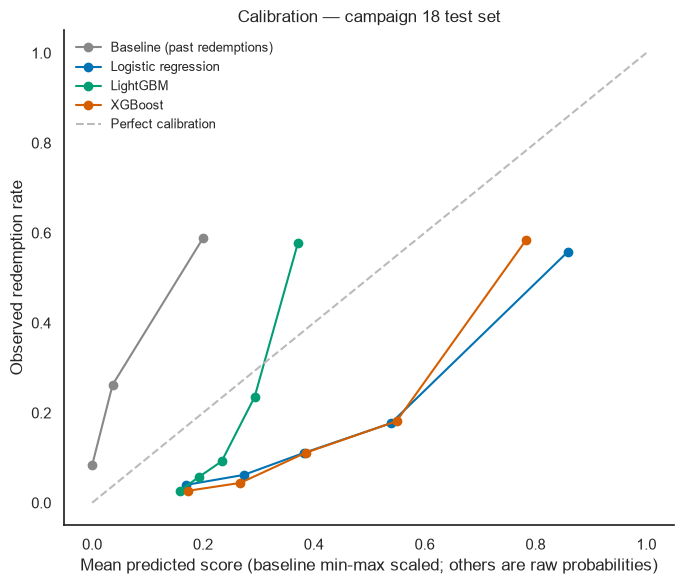

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, score in test_scores.items():
    # The 3 ML models already output genuine probabilities in [0, 1] and are plotted as-is.
    # The baseline is a raw redemption count, not a probability, so it's min-max scaled to
    # [0, 1] purely to be visually comparable on the same axis -- its curve is not a real
    # calibration check, since it was never meant to be a probability.
    plotted_score = score if score.max() <= 1 else score / score.max()
    frac_pos, mean_pred = calibration_curve(y_test, plotted_score, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name, color=MODEL_PALETTE[name])

ax.plot([0, 1], [0, 1], linestyle="--", color="#bbbbbb", label="Perfect calibration")
ax.set_xlabel("Mean predicted score (baseline min-max scaled; others are raw probabilities)")
ax.set_ylabel("Observed redemption rate")
ax.set_title("Calibration — campaign 18 test set")
ax.legend(fontsize=9, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### 8a. Is logistic regression miscalibrated?

The chart above already hints at it: every model's curve sits below the diagonal
(predicted scores running ahead of observed rates). Zooming in on logistic regression's
actual predicted probabilities (not the baseline's rescaled counts) makes it explicit.

In [14]:
proba_logreg_raw = test_scores["Logistic regression"]
proba_xgb_raw = test_scores["XGBoost"]

print(f"Logistic regression -- mean predicted probability: {proba_logreg_raw.mean():.3f} "
      f"vs. actual test redemption rate: {y_test.mean():.3f}")
print(f"XGBoost (the CV-selected winner) -- mean predicted probability: {proba_xgb_raw.mean():.3f} "
      f"vs. actual test redemption rate: {y_test.mean():.3f}")
print()

for name, score in [("Logistic regression", proba_logreg_raw), ("XGBoost", proba_xgb_raw)]:
    frac_pos, mean_pred = calibration_curve(y_test, score, n_bins=5, strategy="quantile")
    print(f"{name} calibration bins (predicted vs. observed):")
    for p, o in zip(mean_pred, frac_pos):
        print(f"  predicted={p:.3f}  observed={o:.3f}  gap={p - o:+.3f}")
    print()


Logistic regression -- mean predicted probability: 0.445 vs. actual test redemption rate: 0.190
XGBoost (the CV-selected winner) -- mean predicted probability: 0.432 vs. actual test redemption rate: 0.190

Logistic regression calibration bins (predicted vs. observed):
  predicted=0.170  observed=0.040  gap=+0.130
  predicted=0.274  observed=0.062  gap=+0.212
  predicted=0.383  observed=0.111  gap=+0.272
  predicted=0.539  observed=0.177  gap=+0.362
  predicted=0.858  observed=0.558  gap=+0.301

XGBoost calibration bins (predicted vs. observed):
  predicted=0.173  observed=0.027  gap=+0.146
  predicted=0.267  observed=0.044  gap=+0.223
  predicted=0.385  observed=0.111  gap=+0.274
  predicted=0.549  observed=0.181  gap=+0.368
  predicted=0.783  observed=0.584  gap=+0.199



**Both are badly miscalibrated, and for the same reason.** Logistic regression's mean
predicted probability is 0.44 against an actual rate of 0.19 (gaps up to +0.36 in some
bins); XGBoost's is 0.43 against the same 0.19, with similarly large gaps. Both models
were deliberately trained to counteract class imbalance — `class_weight="balanced"` for
logistic regression, `scale_pos_weight` for XGBoost — which reweights the loss function
as if positives and negatives were equally common. That's exactly what makes both models
good at *ranking* (it keeps the minority class from being ignored), but it systematically
inflates the predicted probabilities away from the true ~19% base rate. Ranking and
calibration are different properties, and the imbalance correction bought the former at
the cost of the latter.

### 8b. Calibrating the winning model (and logistic regression, for comparison)

`CalibratedClassifierCV` with Platt scaling (`method="sigmoid"`) learns a monotonic
remapping from raw score to true probability, fit on the same grouped CV folds used
throughout. Being monotonic, it should leave ranking metrics (ROC-AUC, PR-AUC, lift)
essentially unchanged while fixing the probability values themselves — refitting without
`class_weight`/`scale_pos_weight` instead would change *which* model is fit, not just
rescale its output, risking the ranking quality that got each model selected in the first
place.

In [15]:
from sklearn.calibration import CalibratedClassifierCV

precomputed_splits = list(group_kfold.split(X_train, y_train, groups_train))

calibrated_logreg = CalibratedClassifierCV(
    Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000))]),
    method="sigmoid", cv=precomputed_splits,
)
calibrated_logreg.fit(X_train, y_train)
proba_logreg_cal = calibrated_logreg.predict_proba(X_test)[:, 1]

calibrated_xgb = CalibratedClassifierCV(
    xgb.XGBClassifier(
        n_estimators=best_xgb_n_estimators, max_depth=int(best_xgb_row["max_depth"]),
        learning_rate=best_xgb_row["learning_rate"], min_child_weight=int(best_xgb_row["min_child_weight"]),
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=full_scale_pos_weight, random_state=RANDOM_STATE,
    ),
    method="sigmoid", cv=precomputed_splits,
)
calibrated_xgb.fit(X_train, y_train)
proba_xgb_cal = calibrated_xgb.predict_proba(X_test)[:, 1]

calibration_comparison = pd.DataFrame(
    {
        "logreg_raw": evaluate_predictions(y_test, proba_logreg_raw),
        "logreg_calibrated": evaluate_predictions(y_test, proba_logreg_cal),
        "xgb_raw": evaluate_predictions(y_test, proba_xgb_raw),
        "xgb_calibrated": evaluate_predictions(y_test, proba_xgb_cal),
    }
).T
calibration_comparison["mean_predicted_proba"] = [
    proba_logreg_raw.mean(), proba_logreg_cal.mean(), proba_xgb_raw.mean(), proba_xgb_cal.mean(),
]
calibration_comparison.round(4)


,roc_auc,pr_auc,top_decile_lift,mean_predicted_proba
logreg_raw,0.8272,0.6230,4.0981,0.4448
logreg_calibrated,0.8261,0.6217,4.0510,0.2026
xgb_raw,0.8430,0.6203,3.7684,0.4316
xgb_calibrated,0.8441,0.6290,3.7213,0.1865


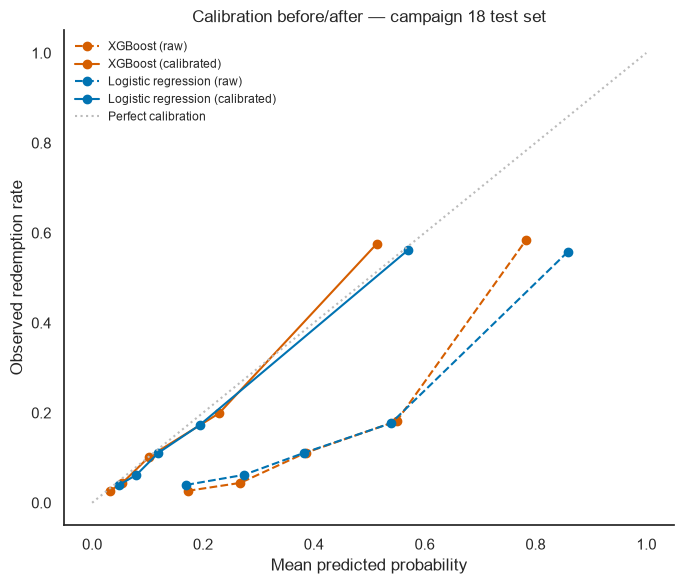

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
curves = [
    ("XGBoost (raw)", proba_xgb_raw, "--", sns.color_palette("colorblind")[3]),
    ("XGBoost (calibrated)", proba_xgb_cal, "-", sns.color_palette("colorblind")[3]),
    ("Logistic regression (raw)", proba_logreg_raw, "--", sns.color_palette("colorblind")[0]),
    ("Logistic regression (calibrated)", proba_logreg_cal, "-", sns.color_palette("colorblind")[0]),
]
for name, score, style, color in curves:
    frac_pos, mean_pred = calibration_curve(y_test, score, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", linestyle=style, color=color, label=name)

ax.plot([0, 1], [0, 1], linestyle=":", color="#bbbbbb", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed redemption rate")
ax.set_title("Calibration before/after — campaign 18 test set")
ax.legend(fontsize=8.5, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


**Calibration is fixed, and ranking is preserved.** XGBoost's mean predicted probability
moves from 0.43 to 0.19 (matching the actual 0.19 rate almost exactly), and its
calibration curve sits right on the diagonal. Ranking metrics barely move — calibrated
XGBoost's ROC-AUC/PR-AUC/lift are 0.844 / 0.629 / 3.72x vs. the raw model's 0.843 / 0.620
/ 3.77x, a wash in either direction. The same holds for logistic regression. **The
calibrated XGBoost model is what's saved as the final propensity score** — the raw model
was fine for ranking households but its probability values (e.g. "this household has a
43% chance of redeeming") would have been misleading taken at face value.

## 9. Cumulative gains chart

X-axis: % of treated households contacted, ranked by score (highest first). Y-axis: % of
all actual redeemers captured so far. The diagonal is what random targeting would achieve.


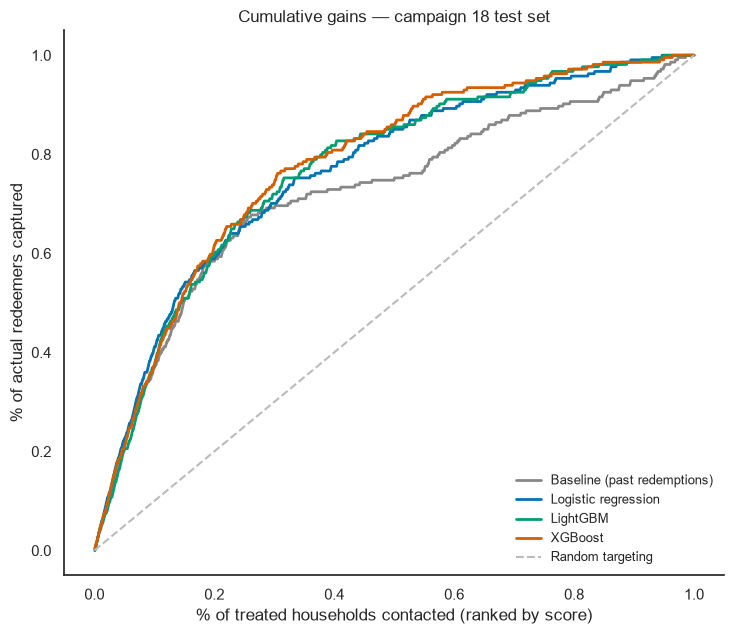

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
y_test_arr = y_test.to_numpy()
total_positives = y_test_arr.sum()

for name, score in test_scores.items():
    order = np.argsort(-score)
    y_sorted = y_test_arr[order]
    cum_gains = np.cumsum(y_sorted) / total_positives
    pct_contacted = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    ax.plot(pct_contacted, cum_gains, label=name, color=MODEL_PALETTE[name], linewidth=2)

ax.plot([0, 1], [0, 1], linestyle="--", color="#bbbbbb", label="Random targeting")
ax.set_xlabel("% of treated households contacted (ranked by score)")
ax.set_ylabel("% of actual redeemers captured")
ax.set_title("Cumulative gains — campaign 18 test set")
ax.legend(fontsize=9, frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## 10. Which model wins?

**XGBoost**, based on the CV comparison in section 7a — it wins ROC-AUC, PR-AUC, and
top-decile lift on cross-validation, which is the only comparison made before the test
set was consulted. (An earlier version of this notebook named logistic regression as the
winner using test-set metrics, where it narrowly edged out XGBoost on PR-AUC and lift;
section 7a explains why that comparison was the wrong one to use and corrects it.)
Logistic regression remains a strong, fully interpretable second choice — on test it's
within noise of XGBoost — and LightGBM, despite collapsing to just 5-12 trees per fold
under early stopping, doesn't match either on CV.


## 11. SHAP — XGBoost (the CV-selected winner)

`TreeExplainer` gives exact SHAP values for XGBoost. Unlike the linear model, no
scaling is needed — SHAP is computed directly on the original-unit features XGBoost was
trained on.

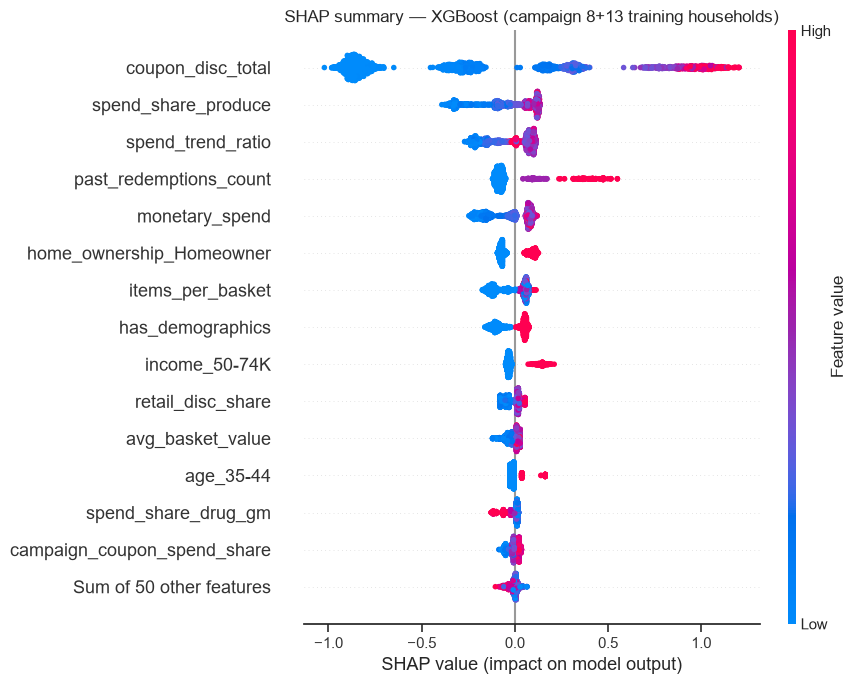

In [18]:
explainer = shap.TreeExplainer(final_xgb)
shap_values = explainer(X_train)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 7)
plt.title("SHAP summary — XGBoost (campaign 8+13 training households)")
plt.tight_layout()
plt.show()


## 12. Top 10 drivers

In [19]:
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURE_COLS)


def shap_direction(feature):
    """Direction isn't a single coefficient for a tree model -- approximate it by the
    correlation between the feature's own value and its own SHAP value across households."""
    idx = FEATURE_COLS.index(feature)
    corr = np.corrcoef(X_train[feature], shap_values.values[:, idx])[0, 1]
    return "higher -> more likely to redeem" if corr > 0 else "higher -> less likely to redeem"


top10 = mean_abs_shap.sort_values(ascending=False).head(10).rename("mean_abs_shap").to_frame()
top10["direction"] = [shap_direction(f) for f in top10.index]
top10


,mean_abs_shap,direction
coupon_disc_total,0.631055,higher -> more likely to redeem
spend_share_produce,0.130017,higher -> more likely to redeem
spend_trend_ratio,0.110636,higher -> more likely to redeem
past_redemptions_count,0.104989,higher -> more likely to redeem
monetary_spend,0.101187,higher -> more likely to redeem
home_ownership_Homeowner,0.080795,higher -> more likely to redeem
items_per_basket,0.078500,higher -> more likely to redeem
has_demographics,0.073736,higher -> more likely to redeem
income_50-74K,0.047653,higher -> more likely to redeem
retail_disc_share,0.029627,higher -> more likely to redeem


## 13. Top 10 drivers, in plain business language

**A note before the list: `coupon_disc_total` and `past_redemptions_count` are
correlated (r = 0.37 on the training data), and their SHAP credit is shared, not
independent.** Both describe the same underlying thing — "has this household used
coupons before" — from slightly different angles (dollars vs. count). When two features
carry overlapping signal, a tree model tends to pick one as the primary split and lean on
it repeatedly, leaving the correlated partner with less *attributed* importance even
though it's still genuinely predictive on its own. That's exactly what happened here:
`coupon_disc_total`'s SHAP magnitude (0.63) dwarfs everything else, including
`past_redemptions_count` (0.11, ranked 4th) — in the logistic regression version of this
analysis (a linear model, which splits correlated credit more evenly instead of
concentrating it), the two were much closer (0.25 and 0.17, ranked 1st and 2nd). Read
`coupon_disc_total`'s outsized rank here as "prior coupon engagement, measured either
way" rather than "redemption count doesn't matter."

1. **`coupon_disc_total`** (higher -> more likely) — prior coupon engagement (in dollars,
   and by extension in count, per the note above) is by far the strongest signal.
2. **`spend_share_produce`** (higher -> more likely) — households who put more of their
   basket toward produce redeem more; a fresh-focused shopping mix tracks with coupon use.
3. **`spend_trend_ratio`** (higher -> more likely) — spend accelerating into the campaign
   predicts redemption, echoing the Stage 3 "Rising spenders" segment's upside potential.
4. **`past_redemptions_count`** (higher -> more likely) — redemption history, net of what
   `coupon_disc_total` already captures (see the note above).
5. **`monetary_spend`** (higher -> more likely) — heavier overall spenders redeem more.
6. **`home_ownership_Homeowner`** (higher -> more likely) — a modest positive skew for
   homeowners, the strongest demographic signal in the top 10.
7. **`items_per_basket`** (higher -> more likely) — larger baskets, more chances the
   couponed product is already in the cart.
8. **`has_demographics`** (higher -> more likely) — simply having a demographics record
   on file predicts redemption; as in Stage 2's covariate-balance check, this looks like a
   proxy for being a known/enrolled loyalty customer rather than a causal driver.
9. **`income_50-74K`** (higher -> more likely) — a specific middle-income band skews
   toward redemption, matching the logistic regression finding.
10. **`retail_disc_share`** (higher -> more likely) — discount-seeking shoppers overall,
    the weakest signal in the top 10.

**The headline for an offers team is unchanged:** redemption propensity is driven mainly
by existing coupon/shopping behavior, with demographics playing a small supporting role
(`home_ownership_Homeowner`, `has_demographics`, `income_50-74K` are all present but far
down the list). The specific ranking shifted between models because of how each one
handles the `coupon_disc_total`/`past_redemptions_count` overlap, but the practical
conclusion — target on behavior, not demographics — holds under both.


## 13a. Does XGBoost actually need the demographic features?

Section 13 claims demographics play only a small supporting role. To check that directly
rather than just reading it off the SHAP ranking, the winning model is refit on the exact
same training data and hyperparameters, with the 45 demographic columns (`age_*`,
`income_*`, `home_ownership_*`, `marital_status_*`, `household_size_*`,
`household_comp_*`, `kids_count_*`, `has_demographics`) removed — down to 19 features.

In [20]:
DEMOGRAPHIC_PREFIXES = (
    "age_", "income_", "home_ownership_", "marital_status_",
    "household_size_", "household_comp_", "kids_count_",
)
demographic_cols = [c for c in FEATURE_COLS if c.startswith(DEMOGRAPHIC_PREFIXES) or c == "has_demographics"]
non_demographic_cols = [c for c in FEATURE_COLS if c not in demographic_cols]

print(f"Demographic columns removed: {len(demographic_cols)}")
print(f"Remaining (behavioral) columns: {len(non_demographic_cols)}")

xgb_no_demo = xgb.XGBClassifier(
    n_estimators=best_xgb_n_estimators, max_depth=int(best_xgb_row["max_depth"]),
    learning_rate=best_xgb_row["learning_rate"], min_child_weight=int(best_xgb_row["min_child_weight"]),
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=full_scale_pos_weight, random_state=RANDOM_STATE,
)
xgb_no_demo.fit(X_train[non_demographic_cols], y_train)
proba_no_demo = xgb_no_demo.predict_proba(X_test[non_demographic_cols])[:, 1]

ablation = pd.DataFrame(
    {
        "XGBoost, all 64 features": evaluate_predictions(y_test, proba_xgb_raw),
        "XGBoost, 19 features (no demographics)": evaluate_predictions(y_test, proba_no_demo),
    }
).T
ablation.round(4)


Demographic columns removed: 45
Remaining (behavioral) columns: 19


,roc_auc,pr_auc,top_decile_lift
"XGBoost, all 64 features",0.8430,0.6203,3.7684
"XGBoost, 19 features (no demographics)",0.8381,0.6201,3.8626


**Dropping all 45 demographic columns costs almost nothing.** PR-AUC is identical to
three decimal places (0.620 either way), ROC-AUC drops marginally (0.843 -> 0.838), and
top-decile lift actually *improves* (3.77x -> 3.86x) with demographics removed. This
backs up the claim directly: the behavioral features alone (RFM, discount/coupon
history, department mix, campaign exposure) carry essentially all of the model's
predictive power. For a targeting program, this matters operationally — only ~32% of
households even have a demographics record (Stage 1), so a model that doesn't depend on
it is more broadly usable, not just simpler.

## 14. Save campaign 18 propensity scores

Using the **calibrated XGBoost** model (section 8b) — the CV-selected winner, with
well-calibrated probabilities rather than the raw imbalance-corrected scores.

In [21]:
propensity_scores = pd.DataFrame(
    {
        "household_id": test["household_id"].values,
        "propensity": proba_xgb_cal,
    }
)
propensity_scores.to_parquet("../data/processed/propensity_scores.parquet", index=False)
propensity_scores.head()


,household_id,propensity
0,1,0.140395
1,2,0.105360
2,6,0.122295
3,7,0.291223
4,8,0.297987


## 15. Does ML beat the simple baseline?

**Yes, consistently, but not by a huge margin — and the honest comparison is on CV, not
test.** The baseline — just ranking by past redemption count — is a surprisingly strong
rule even on CV (ROC-AUC 0.63, PR-AUC 0.33, 3.06x lift), because `past_redemptions_count`
is one of the single best predictors on its own. All three ML models beat it clearly on
CV: XGBoost (the selected winner) reaches CV ROC-AUC 0.81, PR-AUC 0.51, and 3.50x lift —
by combining that same past-redemption signal with RFM, discount behavior, department
mix, spend trend, and campaign-exposure history, it captures real incremental
information the single-feature rule leaves on the table. On the (once-touched) test set,
XGBoost reaches ROC-AUC 0.843, PR-AUC 0.620, and 3.77x lift — comfortably ahead of the
baseline's 0.780 / 0.526 / 3.72x, though logistic regression is close behind XGBoost on
test and should be considered a credible, more interpretable alternative.

**Three corrections from this round of review, all now reflected above:**
1. The winner is **XGBoost, selected on CV** (section 7a/10) — the original call used
   test metrics to compare model families, which risked exactly the kind of test-set
   leakage the single-touch rule exists to prevent.
2. XGBoost's raw probabilities were **badly miscalibrated** by `scale_pos_weight`
   (mean predicted 0.43 vs. actual 0.19) — `CalibratedClassifierCV` (section 8b) fixes
   this while leaving ranking metrics essentially unchanged, and the calibrated model is
   what's saved to `propensity_scores.parquet`.
3. The "demographics aren't needed" claim is now **backed by a direct ablation**
   (section 13a): dropping all 45 demographic columns costs nothing on PR-AUC and
   actually improves top-decile lift.

**Practical takeaway:** for this data volume, a lightly-regularized XGBoost — calibrated,
and trained on behavioral features alone — is the best-performing choice, with logistic
regression a close, more transparent runner-up.
